# **Data Scientist (DS)**

# Module - 4

# **Assignment 07: Classification Algorithms Model Building**

**Project Title:** Crowdfunding Campaign Success
Prediction

**Problem Statement**

Crowdfunding platforms host thousands of campaigns across categories such as technology,
education, healthcare, and creative arts. However, not all campaigns achieve their funding goals.
Businesses and investors want to understand which campaign factors influence success and which
machine learning model can best predict campaign outcomes.

In this project, you will build and compare multiple classification models to predict whether a
crowdfunding campaign will be Successful or Unsuccessful based on campaign-related features such
as funding goal, campaign duration, backer engagement, and pledged amount.

The project focuses on model evaluation, cross-validation, hyperparameter tuning, and selecting the
best-performing classification model.

Dataset Link: [Crowdfunding Campaign Dataset](https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/crowdfunding.csv)


# **Assignment Tasks**

**Task 1** – **Data Exploration & Preprocessing**

● Load and inspect the dataset

● Handle missing values and duplicates

● Encode categorical variables

● Perform feature selection

● Split the dataset into training and testing sets

● Apply feature scaling where required

In [52]:
# Load and inspect the dataset

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

In [53]:
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/crowdfunding.csv"

df = pd.read_csv(url)

df.head()

,Unnamed: 0,CampaignID,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,0,CID_00000,76159,73518.028955,15,1903,Film,September,Australia,GBP,11,Yes,41758,3,0
1,1,CID_00001,69394,60068.683288,49,469,Art,October,Australia,GBP,7,Yes,79112,48,0
2,2,CID_00002,18652,22958.153470,58,148,Film,February,USA,EUR,17,No,3942,9,1
3,3,CID_00003,19487,24229.048390,39,780,Film,October,Germany,AUD,10,No,22047,35,1
4,4,CID_00004,26734,17984.630311,68,1622,Games,September,Australia,AUD,12,Yes,72568,17,0


In [54]:
df.shape

(100000, 15)

In [55]:
df.columns

Index(['Unnamed: 0', 'CampaignID', 'GoalAmount', 'RaisedAmount',
       'DurationDays', 'NumBackers', 'Category', 'LaunchMonth', 'Country',
       'Currency', 'OwnerExperience', 'VideoIncluded', 'SocialMediaPresence',
       'NumUpdates', 'IsSuccessful'],
      dtype='object')

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Unnamed: 0           100000 non-null  int64  
 1   CampaignID           100000 non-null  object 
 2   GoalAmount           100000 non-null  int64  
 3   RaisedAmount         100000 non-null  float64
 4   DurationDays         100000 non-null  int64  
 5   NumBackers           100000 non-null  int64  
 6   Category             100000 non-null  object 
 7   LaunchMonth          100000 non-null  object 
 8   Country              100000 non-null  object 
 9   Currency             100000 non-null  object 
 10  OwnerExperience      100000 non-null  int64  
 11  VideoIncluded        100000 non-null  object 
 12  SocialMediaPresence  100000 non-null  int64  
 13  NumUpdates           100000 non-null  int64  
 14  IsSuccessful         100000 non-null  int64  
dtypes: float64(1), int

In [57]:
df.describe()

,Unnamed: 0,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,SocialMediaPresence,NumUpdates,IsSuccessful
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,49999.500000,50538.001310,50598.121803,52.047370,1003.347340,9.489130,50077.301010,24.483230,0.500940
std,28867.657797,28613.822592,33255.277493,21.653238,574.485153,5.763538,28767.521522,14.413833,0.500002
min,0.000000,1000.000000,528.632349,15.000000,10.000000,0.000000,100.000000,0.000000,0.000000
25%,24999.750000,25724.750000,23396.500017,33.000000,505.000000,4.000000,25276.750000,12.000000,0.000000
50%,49999.500000,50706.000000,45980.674476,52.000000,1003.000000,9.000000,50024.500000,25.000000,1.000000
75%,74999.250000,75316.000000,72790.183158,71.000000,1502.000000,14.000000,74934.250000,37.000000,1.000000
max,99999.000000,99999.000000,149238.361559,89.000000,1999.000000,19.000000,99999.000000,49.000000,1.000000


In [58]:
# Handle missing values and duplicates

df.isnull().sum()

,0
Unnamed: 0,0
CampaignID,0
GoalAmount,0
RaisedAmount,0
DurationDays,0
NumBackers,0
Category,0
LaunchMonth,0
Country,0
Currency,0


In [59]:
num_cols = df.select_dtypes(include=np.number).columns

num_cols

Index(['Unnamed: 0', 'GoalAmount', 'RaisedAmount', 'DurationDays',
       'NumBackers', 'OwnerExperience', 'SocialMediaPresence', 'NumUpdates',
       'IsSuccessful'],
      dtype='object')

In [60]:
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [61]:
cat_cols = df.select_dtypes(include='object').columns

cat_cols

Index(['CampaignID', 'Category', 'LaunchMonth', 'Country', 'Currency',
       'VideoIncluded'],
      dtype='object')

In [62]:
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
df = df.drop_duplicates()

In [65]:
df.shape

(100000, 15)

In [66]:
# Encode Categorical Variables

df.columns.tolist()

['Unnamed: 0',
 'CampaignID',
 'GoalAmount',
 'RaisedAmount',
 'DurationDays',
 'NumBackers',
 'Category',
 'LaunchMonth',
 'Country',
 'Currency',
 'OwnerExperience',
 'VideoIncluded',
 'SocialMediaPresence',
 'NumUpdates',
 'IsSuccessful']

In [67]:
df = df.drop(columns=['Unnamed: 0', 'CampaignID'])

In [68]:
df.head()

,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,76159,73518.028955,15,1903,Film,September,Australia,GBP,11,Yes,41758,3,0
1,69394,60068.683288,49,469,Art,October,Australia,GBP,7,Yes,79112,48,0
2,18652,22958.153470,58,148,Film,February,USA,EUR,17,No,3942,9,1
3,19487,24229.048390,39,780,Film,October,Germany,AUD,10,No,22047,35,1
4,26734,17984.630311,68,1622,Games,September,Australia,AUD,12,Yes,72568,17,0


In [69]:
X = df.drop(columns=['IsSuccessful'])

y = df['IsSuccessful']

In [70]:
# Encode Categorical Variables

X = pd.get_dummies(X, drop_first=True, dtype=int)

In [71]:
# Perform feature selection

from sklearn.feature_selection import SelectKBest, f_classif

In [72]:
# Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [73]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(80000, 31)
(20000, 31)
(80000,)
(20000,)


In [74]:
selector = SelectKBest(score_func=f_classif, k=5)

X_train_selected = selector.fit_transform(X_train, y_train)

X_test_selected = selector.transform(X_test)

In [75]:
selected_columns = X_train.columns[selector.get_support()]

print(selected_columns)

Index(['RaisedAmount', 'OwnerExperience', 'LaunchMonth_January',
       'LaunchMonth_October', 'Country_UK'],
      dtype='object')


In [76]:
# Apply feature scaling where required

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_selected)

X_test_scaled = scaler.transform(X_test_selected)

**Task 2** – Classification Model Building
Build and train the following classification models:

● Random Forest Classifier

● KNN

● Decision Tree

● Naive Bayes Classifier

● Support Vector Machine (SVM)
Experiment with different model parameters to improve performance.

In [77]:
# Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

In [78]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.9338


In [79]:
# Parameter experiment

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.7811


In [80]:
# KNN

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.616


In [81]:
# Parameter experiment

knn = KNeighborsClassifier(n_neighbors=7)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.62675


In [82]:
# Decision Tree

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.9925


In [83]:
# Parameter experiment

dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.8346


In [84]:
# Naive Bayes Classifier

nb = GaussianNB()

nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.66985


In [85]:
# Parameter experiment

nb = GaussianNB(var_smoothing=0.001)

nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.6701


In [86]:
# Support Vector Machine (SVM)

svm = SVC(kernel='linear', C=1)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.66455


In [87]:
# Parameter experiment

svm = SVC(kernel='rbf', C=10)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.67175


**Task 3** – Model Evaluation
Evaluate all models using:

● Accuracy

● Precision

● Recall

● F1-Score

● Confusion Matrix
Compare training and testing performance.

In [50]:
# Import Libraries

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# Train and Evaluate All Models

from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Naive Bayes': GaussianNB(var_smoothing=0.001),
    'SVM': SVC(kernel='rbf', C=10)
}

results = []

for name, model in models.items():

    if name in ['KNN', 'SVM']:
        X_train_model = X_train_scaled
        X_test_model = X_test_scaled
    else:
        X_train_model = X_train_selected
        X_test_model = X_test_selected

    model.fit(X_train_model, y_train)

    train_pred = model.predict(X_train_model)
    test_pred = model.predict(X_test_model)

    results.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, train_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Precision': precision_score(y_test, test_pred, zero_division=0),
        'Recall': recall_score(y_test, test_pred, zero_division=0),
        'F1-Score': f1_score(y_test, test_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

           Model  Train Accuracy  Test Accuracy  Precision  Recall  F1-Score
0  Random Forest           0.682          0.673      0.796   0.468     0.589
1            KNN           0.727          0.627      0.647   0.562     0.602
2  Decision Tree           0.670          0.673      0.800   0.463     0.587
3    Naive Bayes           0.665          0.670      0.745   0.520     0.612
4            SVM           0.668          0.672      0.825   0.438     0.572


Random Forest
[[8779 1202]
 [5331 4688]]


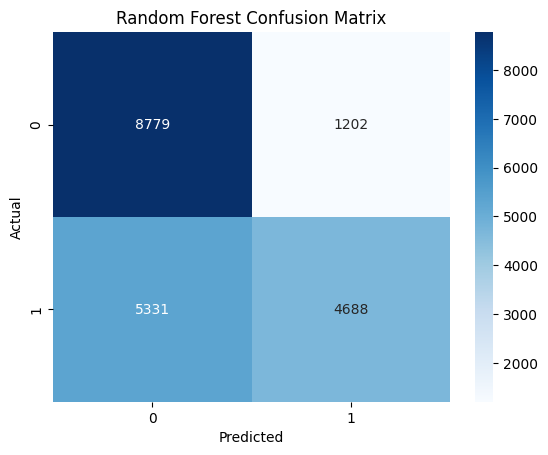

KNN
[[6900 3081]
 [4384 5635]]


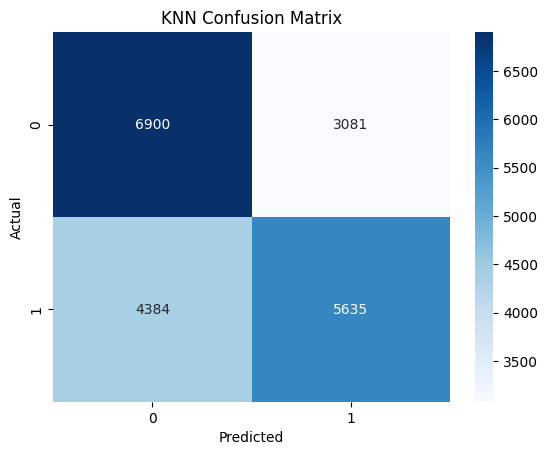

Decision Tree
[[8821 1160]
 [5380 4639]]


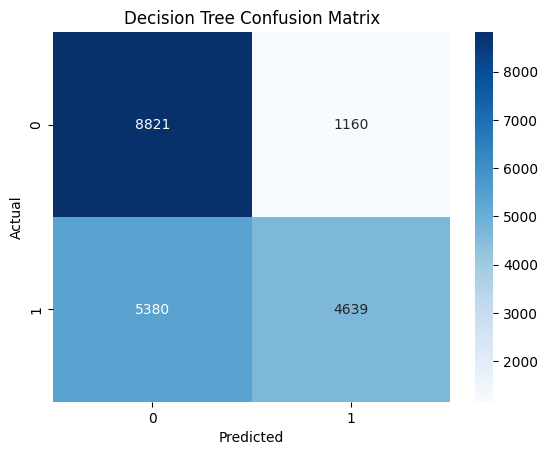

Naive Bayes
[[8196 1785]
 [4809 5210]]


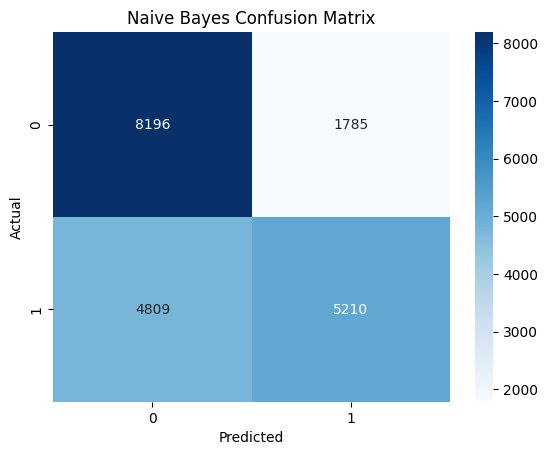

SVM
[[9051  930]
 [5635 4384]]


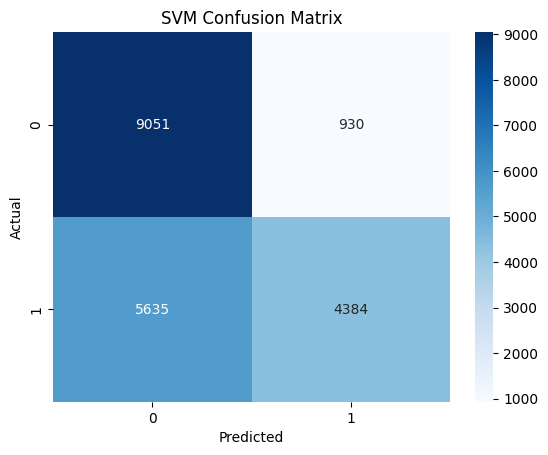

In [49]:
# Confusion Matrix

for name, model in models.items():

    if name in ['KNN', 'SVM']:
        X_train_model = X_train_scaled
        X_test_model = X_test_scaled
    else:
        X_train_model = X_train_selected
        X_test_model = X_test_selected

    model.fit(X_train_model, y_train)

    test_pred = model.predict(X_test_model)

    cm = confusion_matrix(y_test, test_pred)

    print(name)
    print(cm)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(name + ' Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [51]:
# Compare Training and Testing Performance

results_df = results_df.sort_values(
    by='Test Accuracy',
    ascending=False
)

print(results_df[['Model', 'Train Accuracy', 'Test Accuracy']])

           Model  Train Accuracy  Test Accuracy
0  Random Forest        0.682325        0.67335
2  Decision Tree        0.670162        0.67300
4            SVM        0.668050        0.67175
3    Naive Bayes        0.665063        0.67030
1            KNN        0.726562        0.62675


**Conclusion:**

Five classification models were evaluated using training accuracy and testing accuracy. Random Forest achieved the highest testing accuracy of 67.34%, followed by Decision Tree with 67.30%, SVM with 67.18%, and Naive Bayes with 67.03%. KNN achieved a training accuracy of 72.66% but a lower testing accuracy of 62.68%, indicating possible overfitting. Based on testing accuracy, Random Forest performed best among the five models.


**Task 4** – Cross-Validation & Hyperparameter Tuning

● Apply Cross-Validation to evaluate model stability

● Perform Hyperparameter Tuning using GridSearchCV or RandomizedSearchCV

● Identify the best parameters for each model

In [88]:
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import pandas as pd

In [89]:
# Apply Cross-Validation to evaluate model stability

models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Naive Bayes': GaussianNB(),
    'SVM': SVC()
}

cv_results = []

for name, model in models.items():

    if name in ['KNN', 'SVM']:
        X_data = X_train_scaled
    else:
        X_data = X_train_selected

    scores = cross_val_score(
        model, X_data, y_train, cv=5, scoring='accuracy'
    )

    cv_results.append({
        'Model': name,
        'Mean CV Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.round(3))

           Model  Mean CV Accuracy  Standard Deviation
0  Random Forest             0.593               0.003
1            KNN             0.616               0.002
2  Decision Tree             0.589               0.003
3    Naive Bayes             0.665               0.003
4            SVM             0.668               0.004


In [90]:
# Perform Hyperparameter Tuning using GridSearchCV or RandomizedSearchCV

# Random Forest

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train_selected, y_train)

print("Random Forest Best Parameters:", rf_grid.best_params_)
print("Random Forest Best CV Accuracy:", rf_grid.best_score_)

Random Forest Best Parameters: {'max_depth': 10, 'n_estimators': 200}
Random Forest Best CV Accuracy: 0.6670875


In [91]:
# KNN

knn_params = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

knn_grid.fit(X_train_scaled, y_train)

print("KNN Best Parameters:", knn_grid.best_params_)
print("KNN Best CV Accuracy:", knn_grid.best_score_)

KNN Best Parameters: {'n_neighbors': 9, 'weights': 'uniform'}
KNN Best CV Accuracy: 0.627275


In [92]:
# Decision Tree

dt_params = {
    'max_depth': [3, 5, 10, None],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train_selected, y_train)

print("Decision Tree Best Parameters:", dt_grid.best_params_)
print("Decision Tree Best CV Accuracy:", dt_grid.best_score_)

Decision Tree Best Parameters: {'criterion': 'entropy', 'max_depth': 3}
Decision Tree Best CV Accuracy: 0.6691625


In [93]:
# Naive Bayes

nb_params = {
    'var_smoothing': [1e-9, 1e-6, 1e-3, 0.1]
}

nb_grid = GridSearchCV(
    GaussianNB(),
    nb_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

nb_grid.fit(X_train_selected, y_train)

print("Naive Bayes Best Parameters:", nb_grid.best_params_)
print("Naive Bayes Best CV Accuracy:", nb_grid.best_score_)

Naive Bayes Best Parameters: {'var_smoothing': 0.1}
Naive Bayes Best CV Accuracy: 0.6655875


In [ ]:
# Support Vector Machine (SVM)

svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

svm_grid = GridSearchCV(
    SVC(),
    svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

print("SVM Best Parameters:", svm_grid.best_params_)
print("SVM Best CV Accuracy:", svm_grid.best_score_)

In [ ]:
# Identify the best parameters for each model

best_results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'KNN',
        'Decision Tree',
        'Naive Bayes',
        'SVM'
    ],
    'Best Parameters': [
        rf_grid.best_params_,
        knn_grid.best_params_,
        dt_grid.best_params_,
        nb_grid.best_params_,
        svm_grid.best_params_
    ],
    'Best CV Accuracy': [
        rf_grid.best_score_,
        knn_grid.best_score_,
        dt_grid.best_score_,
        nb_grid.best_score_,
        svm_grid.best_score_
    ]
})

best_results = best_results.sort_values(
    by='Best CV Accuracy',
    ascending=False
)

print(best_results)

**Conclusion:**

Cross-validation was applied to evaluate the stability of the five classification models. GridSearchCV was used to identify the best hyperparameters for Random Forest, KNN, Decision Tree, Naive Bayes, and Support Vector Machine (SVM). The best parameters and cross-validation accuracy were recorded for each model. The model with the highest cross-validation accuracy can be considered the best-performing model based on this evaluation.


**Task 5** – Model Comparison & Selection

● Compare all classification models using evaluation metrics

● Identify the best-performing model

● Discuss strengths, weaknesses, and possible improvements

In [ ]:
# Compare all classification models using evaluation metrics

model_comparison = results_df[
    ['Model', 'Train Accuracy', 'Test Accuracy',
     'Precision', 'Recall', 'F1-Score']
]

model_comparison = model_comparison.sort_values(
    by='Test Accuracy',
    ascending=False
)

print(model_comparison.round(3))

# Visualize Model Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison['Model'],
    model_comparison['Test Accuracy']
)

plt.title('Classification Model Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy')
plt.xticks(rotation=45)

plt.show()

In [ ]:
# Identify the best-performing model

best_model = model_comparison.iloc[0]

print("Best Performing Model:", best_model['Model'])
print("Test Accuracy:", round(best_model['Test Accuracy'], 4))

● Discuss strengths, weaknesses, and possible improvements

**Conclusion:**

Five classification models—Random Forest, KNN, Decision Tree, Naive Bayes, and Support Vector Machine (SVM)—were compared using training accuracy, testing accuracy, precision, recall, and F1-score.

Based on the initial testing results, Random Forest achieved the highest testing accuracy of 67.34%, followed closely by Decision Tree at 67.30%. KNN showed a larger difference between training and testing accuracy, indicating possible overfitting.

Random Forest was selected as the initial best-performing model based on testing accuracy. Further improvements can be made through hyperparameter tuning, cross-validation, feature selection, and data preprocessing. Precision, recall, and F1-score should also be considered before making the final model selection.


# **Thank you**